In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} /content/{repo_name}
    os.chdir(f"/content/{repo_name}/2")
    sys.path.insert(0, f"/content/{repo_name}")
    !pip install -q -r /content/{repo_name}/requirements.txt
    !pip install -q -e /content/{repo_name}
    print("環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    proj_root = Path.cwd().resolve()
    if proj_root.name == "2":
        proj_root = proj_root.parent
    if str(proj_root) not in sys.path:
        sys.path.insert(0, str(proj_root))
    print("ローカル実行環境を検出しました。プロジェクトルート:", proj_root)


ローカル実行環境を検出しました。プロジェクトルート: /home/student/Documents/GitHub/study-mikanos


# 2.9 ポインタとアロー演算子 (`Pointers and Arrow Operator`)
## — 構造体メモリレイアウト、アライメント数理、およびコラム 2.2「ポインタのポインタ (`Double Pointer`)」の完全解剖

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/2/2.9_Pointers_and_Arrow_Operator.ipynb)

本節は、『ゼロからのOS自作入門』**第2章 2.9節「ポインタとアロー演算子」**および**コラム 2.2「ポインタのポインタ」**に対応する解説ノートブックです。

前節 2.8 では、メモリの最小単位である1バイトのセル配列、64ビットポインタ変数のサイズ不変性（8バイト固定）、間接参照演算子 `*`、そしてデータ型に応じたポインタ加算のスケーリング数理を学びました。

しかし、実際の OS 開発（UEFI API や MikanOS カーネル）では、単一の整数やバイトだけでなく、複数のデータや関数ポインタを束ねた**「構造体（Struct）」**をポインタ経由で操作する場面が支配的です。

- `gBS->GetMemoryMap(...)`
- `SystemTable->ConOut->OutputString(...)`
- `root_dir->Open(...)`
- `fs->OpenVolume(fs, &root_dir)`

本節では、なぜ構造体ポインタアクセスに**アロー演算子（`->`）**という専用の構文が存在するのか、コンパイラが構造体メンバをメモリ上に配置する際の**アライメント（Alignment）とパディング（Padding）の数理**、そして初心者最大の難所である**コラム 2.2「ポインタのポインタ（二重ポインタ `T**`）」**の動作メカニズムを、スタックフレームとメモリ構造の図解・C++20/Python シミュレーションを通じて徹底的に解き明かします。

---

### 🎯 本節の到達目標 (Learning Objectives)

1. **構造体のメモリ配置とアライメント数理の理解**:
   - 自然アライメント規則（Natural Alignment）とパディングバイトの自動挿入メカニズムを数理的に導出できる。
   - `offsetof` マクロとコンパイラのサイズ決定規則（構造体全体のサイズは最大メンバアライメントの倍数）を正確に計算できる。
2. **アロー演算子（`->`）と間接参照・ドット演算子（`(*p).member`）の完全等価性の習得**:
   - なぜ `*p.member` と書いてはいけないのか（演算子優先順位問題）を説明できる。
   - アロー演算子が x86-64 機械語（`MOV REG, [RDI + offset]`）でどのようにベースレジスタ＋即値オフセット修飾命令に変換されるかを理解する。
3. **コラム 2.2「ポインタのポインタ（二重ポインタ `T**`）」の完全習得**:
   - 値渡し（Pass-by-value）では「呼び出し元のポインタ変数そのもの」を書き換えられない理由をスタックフレーム図で説明できる。
   - UEFI API（`OpenRootDir` や `AllocatePool` 等）がなぜ二重ポインタ（`&root_dir`）を出力引数として要求するのかを理解する。
   - C++ の参照（`T*&`）と C言語 ABI（`T**`）の機械語レベルでの完全一致を検証できる。

---

### 📚 重要技術用語一覧 (Technical Glossary)

| 用語 | 英語正式名称 | 本節での役割・定義 |
|---|---|---|
| **アロー演算子** | **Arrow Operator (`->`)** | 構造体ポインタ経由でメンバにアクセスするためのシンタックスシュガー。`(*p).member` と完全等価。 |
| **ドット演算子** | **Dot Operator (`.`)** | 構造体の実体変数から直接メンバにアクセスする演算子。演算子優先順位が間接参照 `*` より高い。 |
| **自然アライメント** | **Natural Alignment** | $k$ バイトのデータ型を $k$ の倍数番地に配置するハードウェア・コンパイラ要件。 |
| **パディング** | **Padding Bytes** | アライメント要件を満たすために、メンバ間や構造体末尾にコンパイラが挿入する未使用の隙間バイト。 |
| **オフセット** | **Offset** | 構造体の先頭アドレス（Base Address）から各メンバまでの相対バイト距離。 |
| **ポインタのポインタ** | **Pointer to Pointer (`T**`)** | ポインタ変数のメモリアドレスを格納する変数（二重ポインタ）。 |
| **出力引数** | **Output Parameter** | 関数の戻り値ではなく、引数ポインタ経由で呼び出し元にデータを書き戻す引数パターン。 |
| **演算子優先順位** | **Operator Precedence** | 式の中で複数の演算子が競合した際に優先して評価される順序規則。 |


## 2.9.1 なぜ構造体ポインタとアロー演算子が必要なのか？（動機と課題）

### 1. OS 開発における構造体の必然性

前節 2.8 では、1バイトの `char` や 8バイトの `uint64_t` といった基本データ型のポインタを扱いました。しかし、OS カーネルやファームウェアが管理するハードウェア情報は、単一の数値では表現できません。

例えば、MikanOS 第2章で取得した「メモリマップ」を管理するには、以下の情報をひとまとめにして扱う必要があります：

```cpp
struct MemoryMap {
    unsigned long long buffer_size;
    void* buffer;
    unsigned long long map_size;
    unsigned long long map_key;
    unsigned long long descriptor_size;
    unsigned int descriptor_version;
};
```

このように、意味的に関連する複数の異なるデータ型を1つのまとまりとして名前を付けたものが**構造体（`struct`）**です。

### 2. なぜ「構造体の実体」ではなく「構造体ポインタ」を渡すのか？

関数に構造体を渡す際、実体（値）渡しにすると、構造体の全メンバのバイト列がスタックフレームに丸ごとコピーされます。
`MemoryMap` 構造体は 48 バイト、UEFI の `EFI_SYSTEM_TABLE` や `EFI_BOOT_SERVICES` は数百バイトから数キロバイトに及びます。これを関数呼び出しのたびにコピーするのは、CPU 時間と貴重なスタック領域の重大な浪費です。

さらに決定的なのは、**「関数内で構造体の中身を書き換えてもらいたい」**場合です。
値渡しでは呼び出し元の変数を更新できません。したがって、低レイヤプログラミングでは、構造体そのものをコピーするのではなく、**「構造体の先頭アドレス（ポインタ: わずか8バイト）」**を渡すのが絶対の基本原則となります。

```cpp
// 実体渡し (コピーが発生し、関数内で map を書き換えても呼び出し元は変化しない)
EFI_STATUS BadGetMemoryMap(struct MemoryMap map);

// ポインタ渡し (8バイトのアドレス渡し、関数内で呼び出し元の map を直接更新可能)
EFI_STATUS GetMemoryMap(struct MemoryMap* map);
```

### 3. アロー演算子誕生の歴史的背景：演算子優先順位の罠

構造体ポインタ `map` を受け取った関数内でメンバ `buffer_size` にアクセスしたいとします。
ポインタが指す実体を取り出す演算子は `*`（間接参照 / デリファレンス）、メンバにアクセスする演算子は `.`（ドット演算子）です。

素直に書くと、以下のように書きたくなります：

```cpp
*map.buffer_size = 1024;  // コンパイルエラー！
```

なぜこれがコンパイルエラーになるのでしょうか？
その理由は、C/C++ 言語仕様における**演算子優先順位（Operator Precedence）**にあります。

```text
優先順位 第1位 (最高): ドット演算子 (.)
優先順位 第2位:       間接参照演算子 (*)
```

コンパイラは `*map.buffer_size` を、以下のように解釈してしまいます：

$$	ext{*map.buffer_size} \quad \Longrightarrow \quad 	ext{*(map.buffer_size)}$$

つまり、「まず `map` の中の `buffer_size` というメンバを取り出し、それをデリファレンスせよ」という意味になってしまいます。しかし、`map` は構造体の実体ではなく**アドレス（ポインタ変数）**ですから、`map` 自体にはメンバなど存在せず、即座にコンパイルエラーとなります。

正しく解釈させるには、括弧をつけて `*` を先に評価させる必要があります：

```cpp
(*map).buffer_size = 1024;  // 正しいが、括弧とアスタリスクが煩わしい！
```

OS やシステムプログラミングでは、1行の中に何十回も構造体ポインタアクセスが登場します。そのたびに `(*p).a = (*p).b + (*p).c;` と書くのは、可読性を著しく害し、タイピングミスを誘発します。

そこで、**「ポインタを間接参照してそのメンバを指す」**という一連の操作をスマートに記述するために導入された構文（シンタックスシュガー）が、矢印の形をした**アロー演算子（`->`）**です！

```cpp
map->buffer_size = 1024;  // (*map).buffer_size と完全に同等！
```


## 2.9.2 構造体のメモリレイアウトとアライメント・パディング数理

### 1. 自然アライメント規則（Natural Alignment）

「構造体のメンバはメモリ上でどのように配置されているか？」
一見すると、宣言されたメンバのサイズが先頭から隙間なく順番に詰められているように思えます。しかし、現代の CPU（x86-64 や ARM64）では、メモリバスの物理的配線とキャッシュライン（64バイト単位）の効率的な読み書きのため、以下の**自然アライメント規則**が厳格に適用されます。

> [!IMPORTANT]
> **自然アライメント要件 (Natural Alignment Requirement)**:  
> $k$ バイトの基本データ型（2バイトの `short`、4バイトの `int`、8バイトの `uint64_t` / ポインタ）は、**必ずアドレスが $k$ の倍数（$	ext{Address} \pmod k == 0$）となる番地**に配置されなければならない。

もし 8 バイトの整数が奇数番地や 4 バイト境界を跨いで配置されると（未整列アクセス / Unaligned Access）、CPU は 2 回のメモリバスターンとビットシフト・マスク処理を行って結合しなければならず、メモリアクセス性能が激減します（アーキテクチャによってはアライメント例外 `#AC` を発生してクラッシュします）。

### 2. パディング（Padding）の発生数理

コンパイラはメンバのアライメント要件を満たすため、メンバとメンバの間に自動的に「未使用の隙間バイト（**パディング / Padding**）」を挿入します。

現在のオフセットを $	ext{Offset}$、次のメンバのアライメント要件を $	ext{Align}$ とすると、挿入されるパディングバイト数 $	ext{Pad}$ は以下の合同式で求められます：

$$	ext{Pad} = (	ext{Align} - (	ext{Offset} \pmod{	ext{Align}})) \pmod{	ext{Align}}$$

次のメンバの配置オフセットは以下のようになります：

$$	ext{Offset}_{	ext{next}} = 	ext{Offset} + 	ext{Pad}$$

### 3. 具体例：メンバ配置のステップ導出

以下の構造体を例にとり、各メンバの配置オフセットを計算してみましょう：

```cpp
struct SampleStruct {
    uint32_t a;  // 4バイト (アライメント 4)
    uint8_t  b;  // 1バイト (アライメント 1)
    uint16_t c;  // 2バイト (アライメント 2)
    uint64_t d;  // 8バイト (アライメント 8)
};
```

| メンバ | サイズ | アライメント | 配置前オフセット | 必要なパディング | 確定オフセット | 占有メモリ範囲 |
|---|:---:|:---:|:---:|:---:|:---:|:---:|
| `uint32_t a` | 4 B | 4 B | `0` | `0` | **`0`** | `0` 〜 `3` (4B) |
| `uint8_t b` | 1 B | 1 B | `4` | `0` | **`4`** | `4` 〜 `4` (1B) |
| *(Padding)* | 1 B | - | `5` | - | - | `5` 〜 `5` (**1B 隙間**) |
| `uint16_t c` | 2 B | 2 B | `6` (`5+1`) | `1` | **`6`** | `6` 〜 `7` (2B) |
| `uint64_t d` | 8 B | 8 B | `8` | `0` | **`8`** | `8` 〜 `15` (8B) |

### 4. 構造体全体のサイズ決定則（末尾パディング）

メンバ `d` の配置が終わった時点で、合計オフセットは $8 + 8 = 16$ バイトです。
ここで重要なルールがあります：

> [!NOTE]
> **構造体全体のサイズ規則**:  
> 構造体全体のサイズ $	ext{TotalSize}$ は、構造体に含まれる**全メンバの中で最大のメンバアライメント（$	ext{MaxAlign}$）の倍数**に切り上げられなければならない。
>
> $$	ext{TotalSize} = \left\lceil rac{	ext{CurrentOffset}}{	ext{MaxAlign}} ightceil 	imes 	ext{MaxAlign}$$

なぜ末尾パディングが必要なのでしょうか？
それは、**「この構造体の配列（Array）を作成したとき」**を考えれば一目瞭然です。
配列の要素 `arr[0]` と `arr[1]` はメモリ上で隙間なく並びます。もし構造体全体のサイズが最大アライメントの倍数になっていないと、2番目の要素 `arr[1]` の先頭アドレスがアライメント境界からずれてしまい、配列内のメンバ `d` がアライメント違反を起こしてしまうからです。

`SampleStruct` の最大アライメントは `uint64_t d` の 8 バイトです。現在のオフセット 16 はすでに 8 の倍数であるため、末尾パディングは 0 バイトとなり、構造体全体のサイズは **16 バイト** で確定します。


## 2.9.3 アロー演算子 `->` と間接参照・ドット `(*p).member` の完全等価性

### 1. C/C++ 言語レベルでの恒等性

言語規格（ISO C++ / C99）上、アロー演算子は以下のように定義されています：

$$p	ext{->}	ext{member} \quad \equiv \quad (*p).	ext{member}$$

両者はコンパイラにとって構文木（AST: Abstract Syntax Tree）の段階で完全に同一視され、生成される機械語バイナリに何1つ違いはありません。

### 2. x86-64 機械語・アセンブリレベルの動作解剖

CPU のハードウェア（ALU やデコーダ）には、「アロー演算子命令」というものは存在しません。
コンパイラは、アロー演算子を**「ベースレジスタ＋即値オフセット修飾」**のアドレス指定命令に翻訳します。

```text
例: 関数 void inspect(SampleStruct* p) が呼び出されたとき
    (System V AMD64 ABI に従い、第1引数 p は RDI レジスタで渡される)

C++ ソースコード:
    uint64_t val = p->d;

x86-64 アセンブリ命令:
    MOV RAX, [RDI + 8]   ; RDI (ベースアドレス) に offsetof(SampleStruct, d) = 8 を加算し、
                         ; その物理メモリアドレスから 8 バイトを RAX にロード！
```

数式で表すと、アロー演算子がアクセスする実効メモリアドレス $	ext{EffectiveAddress}$ は以下の通りです：

$$	ext{EffectiveAddress}(p	ext{->}	ext{member}) = 	ext{reinterpret\_cast<uintptr\_t>}(p) + 	ext{offsetof}(	ext{StructType}, 	ext{member})$$

値の読み出しは、このアドレスをメンバ型のポインタにキャストしてデリファレンスすることと完全に等価です：

$$	ext{Value} = *(	ext{reinterpret\_cast<MemberType*>}(	ext{EffectiveAddress}))$$

### 3. ドット演算子との機械語の違い

- **ドット演算子（`s.member`）**:
  実体変数 `s` がローカル変数（スタック）の場合、そのアドレスはスタックポインタ `RSP` からの固定相対位置（例: `[RBP - 16]`）になります。コンパイル時に絶対的なオフセットが決定されます。
- **アロー演算子（`p->member`）**:
  ポインタ変数 `p` はヒープ、他の関数のスタック、あるいは UEFI ファームウェア内の任意のメモリアドレスを指している可能性があります。したがって、実行時にレジスタに入っているベースアドレスに、構造体定義から定まるメンバのオフセットを加算して間接アクセスします。


図 2.17 を高解像度 (DPI 300) で生成しました: result/fig2_17_struct_memory_layout_and_arrow_operator.png


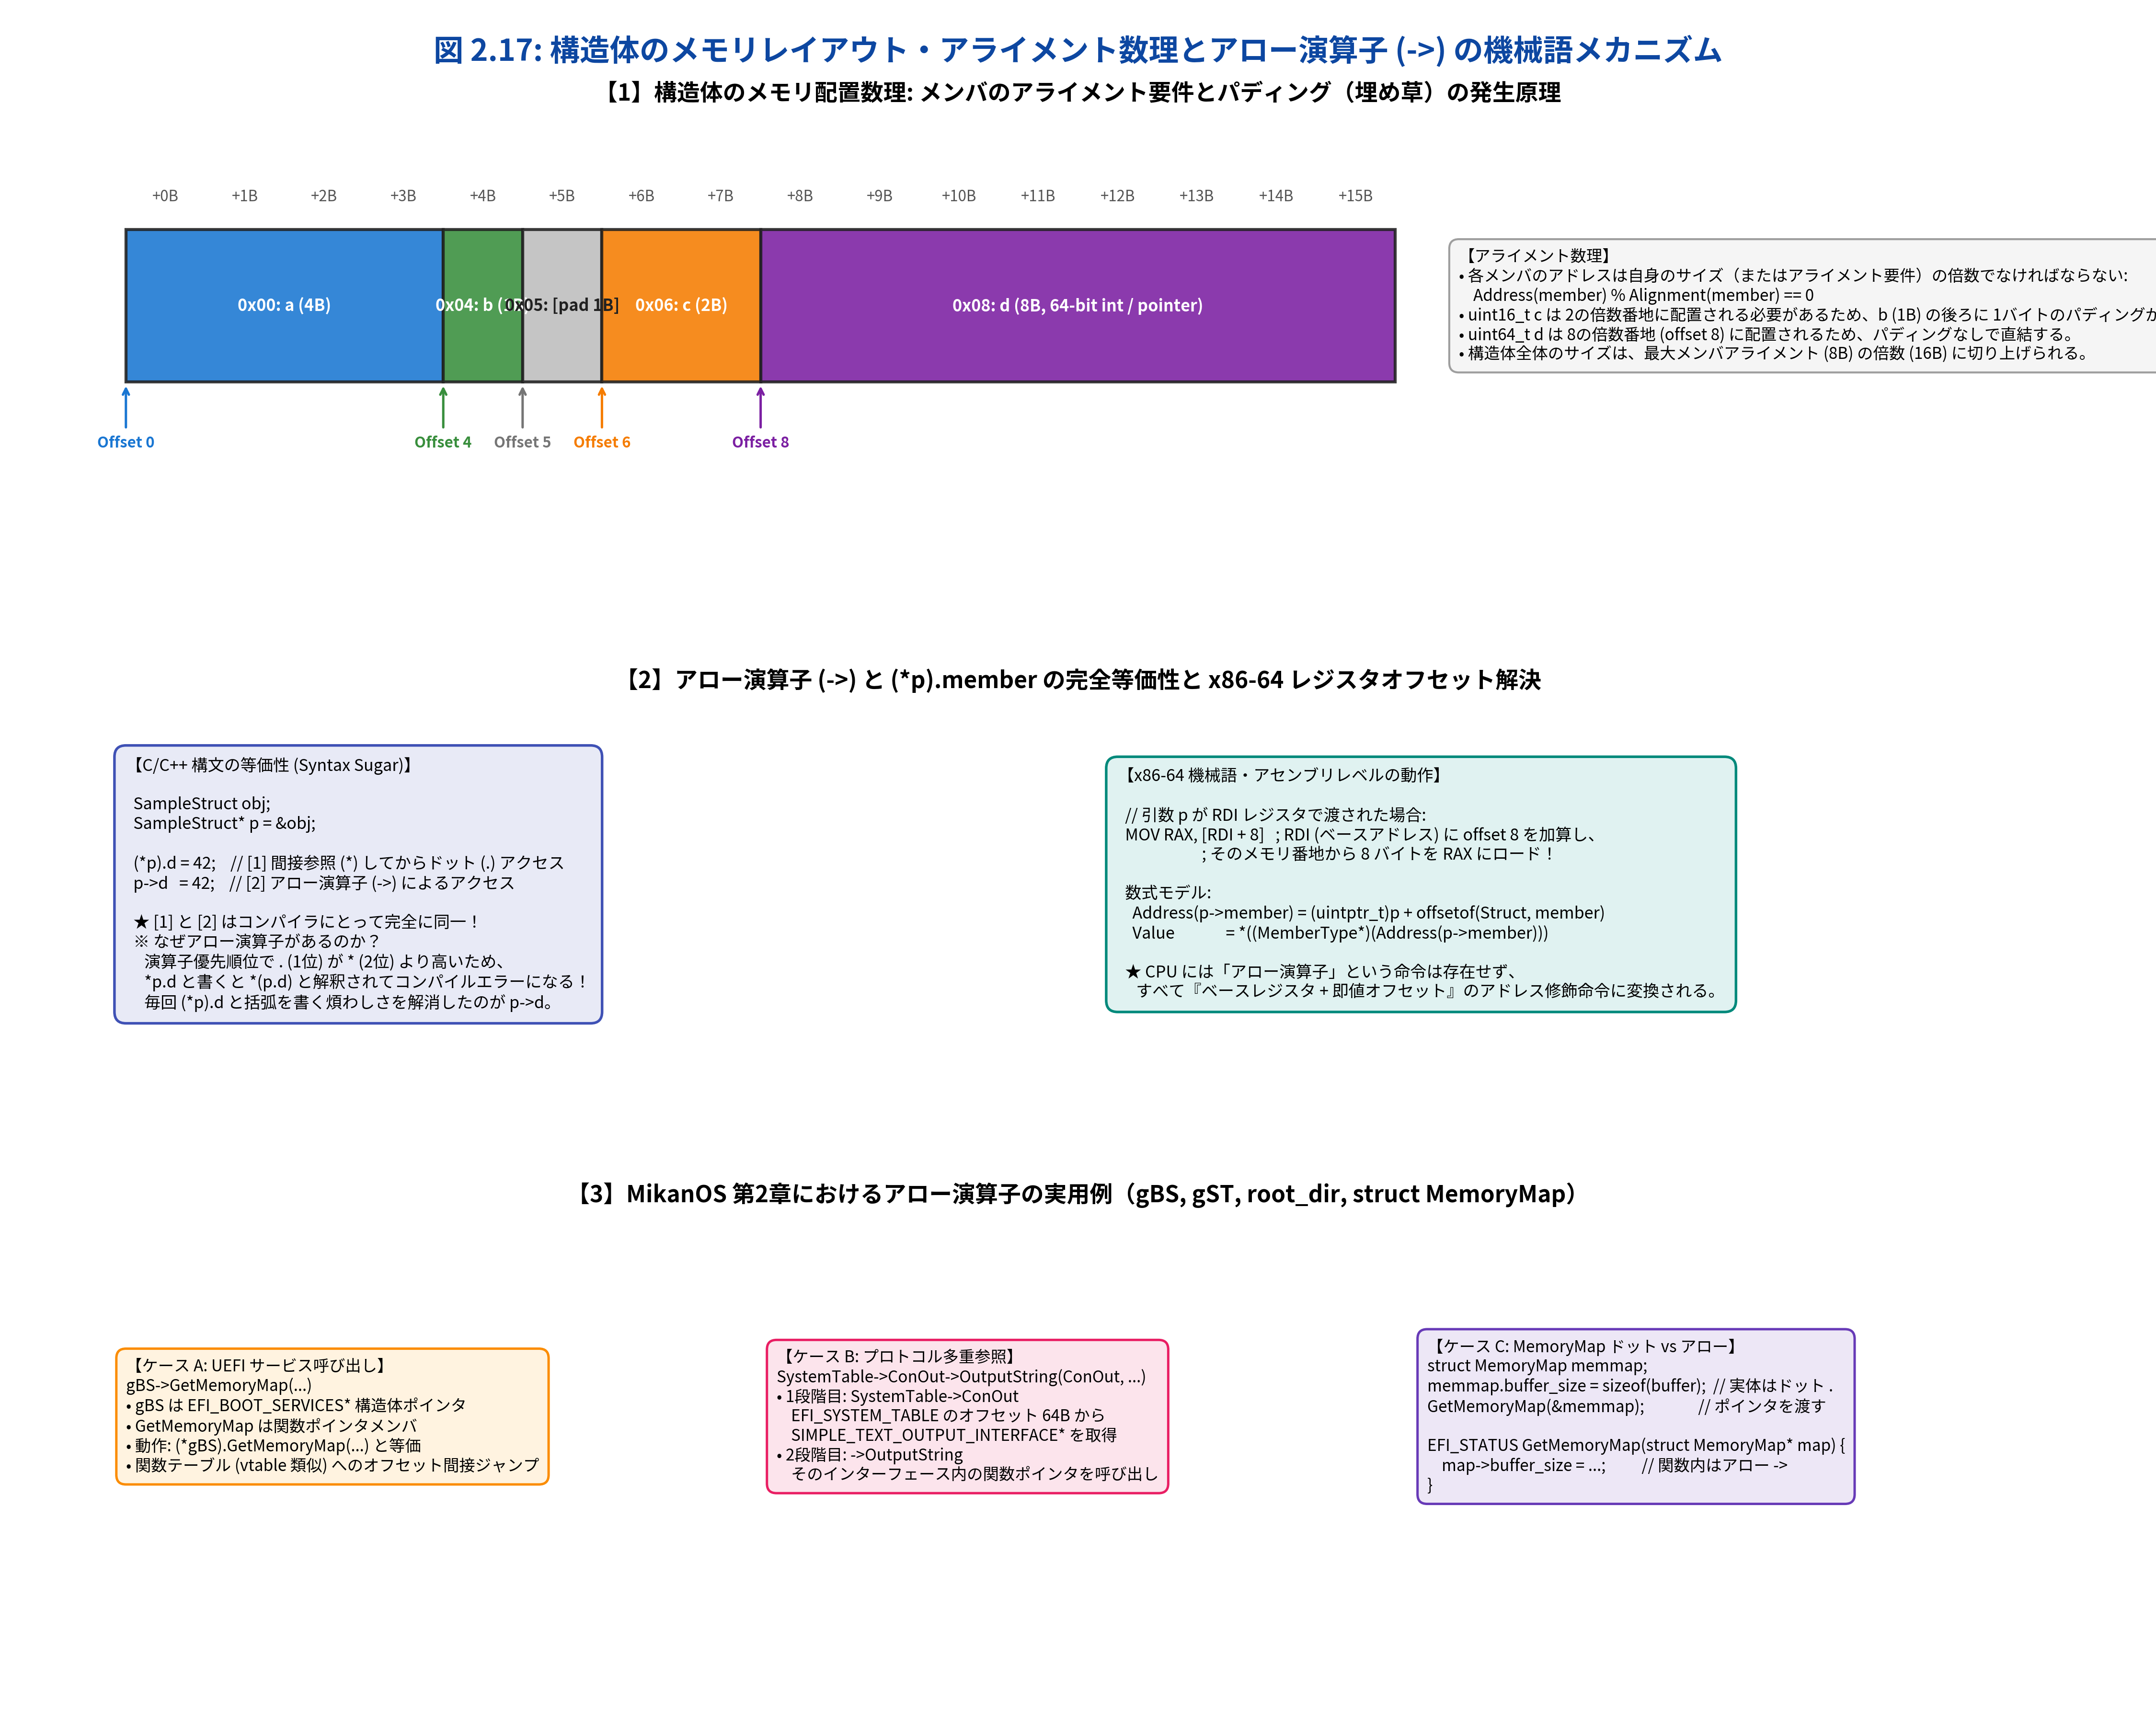

In [2]:
# 高解像度図版 Figure 2.17 の生成とインライン表示
from common.os_sim import plot_figure_2_17_struct_layout_and_arrow_operator
from IPython.display import Image, display

fig2_17_path = "result/fig2_17_struct_memory_layout_and_arrow_operator.png"
plot_figure_2_17_struct_layout_and_arrow_operator(fig2_17_path)
print(f"図 2.17 を高解像度 (DPI 300) で生成しました: {fig2_17_path}")
display(Image(filename=fig2_17_path, width=950))


## 2.9.4 MikanOS 第2章におけるアロー演算子の実用例

MikanOS のブートローダ（`day02a` 〜 `day02b`）のコードには、至る所に構造体ポインタとアロー演算子が登場します。その代表例を分類してみましょう。

### ケース A: UEFI ブートサービスの呼び出し (`gBS->GetMemoryMap`)

```cpp
gBS->GetMemoryMap(
    &memmap.map_size,
    (EFI_MEMORY_DESCRIPTOR*)memmap.buffer,
    &memmap.map_key,
    &memmap.descriptor_size,
    &memmap.descriptor_version
);
```

- `gBS` は `EFI_BOOT_SERVICES*` という構造体ポインタ（グローバル変数）です。
- `EFI_BOOT_SERVICES` 構造体の中には、UEFI ファームウェアが提供する数百の関数ポインタが並んでいます。
- `gBS->GetMemoryMap(...)` は、構造体の先頭から `GetMemoryMap` メンバのオフセット（UEFI 仕様で規定）に位置する関数ポインタを読み出し、そこへ間接コール（`CALL [RAX + offset]`）する処理です。C++ の仮想関数テーブル（vtable）と全く同じ仕組みです。

### ケース B: プロトコル多重参照 (`SystemTable->ConOut->OutputString`)

第1章のハローワールドや第2章初期で登場した以下の呼び出し：

```cpp
SystemTable->ConOut->OutputString(SystemTable->ConOut, L"Hello, World!\n");
```

ここではアロー演算子が2回連続で使われています：
1. `SystemTable->ConOut`: `EFI_SYSTEM_TABLE*` から `ConOut` メンバ（オフセット 64B）に格納されているコンソール出力構造体ポインタ `SIMPLE_TEXT_OUTPUT_INTERFACE*` を取り出す。
2. `->OutputString(...)`: その構造体ポインタ内の関数ポインタメンバ `OutputString` を呼び出す。

### ケース C: `MemoryMap` におけるドット演算子とアロー演算子の使い分け

第2章 2.5節で作成した `struct MemoryMap` の利用コードを振り返ってみましょう：

```cpp
// 1. UefiMain (呼び出し元)
struct MemoryMap memmap = {sizeof(memmap_buf), memmap_buf, 0, 0, 0, 0};
GetMemoryMap(&memmap);  // 実体のアドレス (&) を渡す

// 2. GetMemoryMap 関数 (受け取り側)
EFI_STATUS GetMemoryMap(struct MemoryMap* map) {
    // map はポインタなので、アロー演算子でアクセス！
    if (map->buffer == NULL) {
        return EFI_BUFFER_TOO_SMALL;
    }
    map->map_size = map->buffer_size;
    return gBS->GetMemoryMap(
        &map->map_size,
        (EFI_MEMORY_DESCRIPTOR*)map->buffer,
        &map->map_key,
        &map->descriptor_size,
        &map->descriptor_version
    );
}
```

- `UefiMain` 内では、`memmap` はスタック上に実体として確保されているため、初期化時はドット演算子（`memmap.buffer_size`）を使います。
- 関数 `GetMemoryMap` に渡す際は、実体のアドレス `&memmap`（ポインタ）を渡します。
- 関数内では、引数 `map` はポインタ型（`struct MemoryMap*`）であるため、すべて**アロー演算子（`map->buffer_size` 等）**でアクセスします。


In [3]:
# Python シミュレータによる構造体レイアウトとアロー演算子オフセット計算の実証
from common.os_sim import StructMemoryLayout

# 1. サンプル構造体のレイアウト計算
layout_sample = StructMemoryLayout("SampleStruct", [
    ("a", "uint32_t"),
    ("b", "uint8_t"),
    ("c", "uint16_t"),
    ("d", "uint64_t"),
])

print("=================================================================")
print(f"構造体: {layout_sample.struct_name}")
print(f"合計サイズ: {layout_sample.total_size} バイト, 最大アライメント: {layout_sample.struct_alignment} バイト")
print("=================================================================")
for m in layout_sample.members:
    print(f"  メンバ: {m.name:<12} 型: {m.type_name:<10} サイズ: {m.size}B  アライメント: {m.alignment}B  "
          f"パディング: {m.padding_before}B  -> 確定オフセット: {m.offset} (0x{m.offset:02X})")

# アロー演算子 p->d のアセンブリシミュレーション
base_addr = 0x7FFF_0040
eff_addr, offset, asm = layout_sample.simulate_arrow_operator(base_addr, "d")
print(f"\n[アロー演算子シミュレーション: p->d]")
print(f"  ベースアドレス (p)       : 0x{base_addr:X}")
print(f"  オフセット (offsetof)    : +{offset} バイト")
print(f"  実効メモリアドレス       : 0x{eff_addr:X}")
print(f"  翻訳される機械語命令     : {asm}")

# 2. MikanOS MemoryMap 構造体のレイアウト計算
layout_memmap = StructMemoryLayout("MemoryMap", [
    ("buffer_size", "UINTN"),
    ("buffer", "void*"),
    ("map_size", "UINTN"),
    ("map_key", "UINTN"),
    ("descriptor_size", "UINTN"),
    ("descriptor_version", "UINT32"),
])

print("\n=================================================================")
print(f"構造体: {layout_memmap.struct_name} (MikanOS 第2章)")
print(f"合計サイズ: {layout_memmap.total_size} バイト, 最大アライメント: {layout_memmap.struct_alignment} バイト")
print("=================================================================")
for m in layout_memmap.members:
    print(f"  メンバ: {m.name:<20} 型: {m.type_name:<8} サイズ: {m.size}B  "
          f"オフセット: {m.offset:<2} (0x{m.offset:02X})")


構造体: SampleStruct
合計サイズ: 16 バイト, 最大アライメント: 8 バイト
  メンバ: a            型: uint32_t   サイズ: 4B  アライメント: 4B  パディング: 0B  -> 確定オフセット: 0 (0x00)
  メンバ: b            型: uint8_t    サイズ: 1B  アライメント: 1B  パディング: 0B  -> 確定オフセット: 4 (0x04)
  メンバ: c            型: uint16_t   サイズ: 2B  アライメント: 2B  パディング: 1B  -> 確定オフセット: 6 (0x06)
  メンバ: d            型: uint64_t   サイズ: 8B  アライメント: 8B  パディング: 0B  -> 確定オフセット: 8 (0x08)

[アロー演算子シミュレーション: p->d]
  ベースアドレス (p)       : 0x7FFF0040
  オフセット (offsetof)    : +8 バイト
  実効メモリアドレス       : 0x7FFF0048
  翻訳される機械語命令     : MOV RAX, [RDI + 8]  ; RDI holds base_address 0x7FFF0040

構造体: MemoryMap (MikanOS 第2章)
合計サイズ: 48 バイト, 最大アライメント: 8 バイト
  メンバ: buffer_size          型: UINTN    サイズ: 8B  オフセット: 0  (0x00)
  メンバ: buffer               型: void*    サイズ: 8B  オフセット: 8  (0x08)
  メンバ: map_size             型: UINTN    サイズ: 8B  オフセット: 16 (0x10)
  メンバ: map_key              型: UINTN    サイズ: 8B  オフセット: 24 (0x18)
  メンバ: descriptor_size      型: UINTN    サイズ: 8B  オフセット: 32 (0x20)
  メンバ: descriptor_

## 2.9.5 コラム 2.2: ポインタのポインタ（二重ポインタ `T**`）の完全解剖

みかん本第2章のコラム 2.2 で取り上げられている**「ポインタのポインタ（二重ポインタ）」**は、C言語および低レイヤプログラミングにおける最重要トピックの1つです。

### 1. ポインタのポインタとは何か？

「ポインタ」とは何だったでしょうか？
前節 2.8 で学んだ通り、**「ある変数が置かれているメモリのアドレスを格納する変数」**です。

では、**「ポインタ変数自身」はどこに置かれているでしょうか？**
もちろん、ポインタ変数自身も CPU のメインメモリ（通常はスタック領域）の上に確保された 8 バイト（64ビット環境）のデータ領域に置かれています。
変数である以上、**「ポインタ変数自身にもメモリアドレスが存在する」**のです！

その「ポインタ変数自身のアドレス」を格納する変数のことを、**「ポインタのポインタ（二重ポインタ / Double Pointer）」**と呼びます。

```text
[メモリ空間モデル]

番地 0x1000 : [ 42 ]                int x = 42;
                 ^
                 | (アドレス 0x1000 を格納)
番地 0x2000 : [ 0x0000000000001000 ] int* p = &x;
                 ^
                 | (アドレス 0x2000 を格納)
番地 0x3000 : [ 0x0000000000002000 ] int** pp = &p;
```

### 2. デリファレンス `*` の段階的評価

二重ポインタ `pp` に対する間接参照演算子 `*` は、以下のように1段階ずつアドレスの鎖（チェーン）を辿ります：

1. **`pp`（評価値: `0x2000`）**:
   `p` というポインタ変数が置かれているメモリアドレス。
2. **`*pp`（評価値: `0x1000`）**:
   `0x2000` 番地の中身を読み出す。中身は `x` のアドレス（ポインタ `p` の値そのもの）。
3. **`**pp`（評価値: `42`）**:
   さらに `0x1000` 番地の中身を読み出す。最終目的地である `x` の値（`42`）に到達する！

```cpp
int x = 42;
int* p = &x;
int** pp = &p;

std::cout << x     << std::endl;  // 42
std::cout << *p    << std::endl;  // 42
std::cout << **pp   << std::endl;  // 42 (*pp が p、**pp が x)
```


## 2.9.6 引数渡しの3形態：値渡し vs ポインタ渡し vs 二重ポインタ渡し

なぜ OS 自作において二重ポインタが必要になるのでしょうか？
「趣味でポインタのポインタを繋げて遊びたいから」ではありません。**「関数の中から呼び出し元のポインタ変数の値を書き換えてもらうため」**です。

引数渡しの3つの形態を比較すると、二重ポインタの必然性が完璧に理解できます。

---

### パターン 1: 通常の値渡し（Pass by Value）
```cpp
void IncrementValue(int x) {
    x = x + 1;  // 引数スタックのコピーを変更
}

int a = 10;
IncrementValue(a);
// a は 10 のまま！ (関数側のローカルコピーが変わっただけ)
```

---

### パターン 2: ポインタ渡し（Pass by Pointer）
「呼び出し元の変数 `a` を書き換えたい」なら、`a` のアドレス `&a`（ポインタ）を渡します。
```cpp
void IncrementPointer(int* p) {
    *p = *p + 1;  // p が指す先 (呼び出し元の a) を直接書き換え！
}

int a = 10;
IncrementPointer(&a);
// a は 11 に書き換わる！ (大成功)
```

---

### パターン 3: ポインタの値渡し（最大の落とし穴！）
では、**「ポインタ変数 `ptr` が指す先を、関数内で新しいオブジェクトのアドレスに変えたい」**場合はどうでしょうか？
初心者が必ずやってしまう間違いがこれです：

```cpp
void BadAllocate(MockProtocol* p) {
    p = &new_object;  // 関数の引数 p (コピー) を変更
}

MockProtocol* root = nullptr;
BadAllocate(root);
// root は nullptr のまま！ 致命的バグ (ぬるぽでOSがクラッシュ)
```

なぜ `root` は変わらないのでしょうか？
関数の引数 `MockProtocol* p` に渡されたのは、`root` の中身（`nullptr`）という**「値のコピー」**に過ぎないからです。関数内で `p` に新しいアドレスを代入しても、書き換わったのは関数のスタックフレーム上にある一時変数 `p` だけであり、呼び出し元の `root` には何の影響もありません。

---

### パターン 4: 二重ポインタ渡し（正解！）
呼び出し元のポインタ変数 `root` そのものを書き換えたいなら、**「ポインタ変数 `root` のアドレス（`&root`）」**を関数に渡さなければなりません！

```cpp
void GoodAllocate(MockProtocol** pp) {
    *pp = &new_object;  // pp が指す先 (呼び出し元の root 変数) にアドレスを直接書き込む！
}

MockProtocol* root = nullptr;
GoodAllocate(&root);  // root のアドレス (&root: 二重ポインタ) を渡す！
// root は &new_object を指すように正しく更新される！ (大成功)
```


図 2.18 を高解像度 (DPI 300) で生成しました: result/fig2_18_double_pointer_and_uefi_interface.png


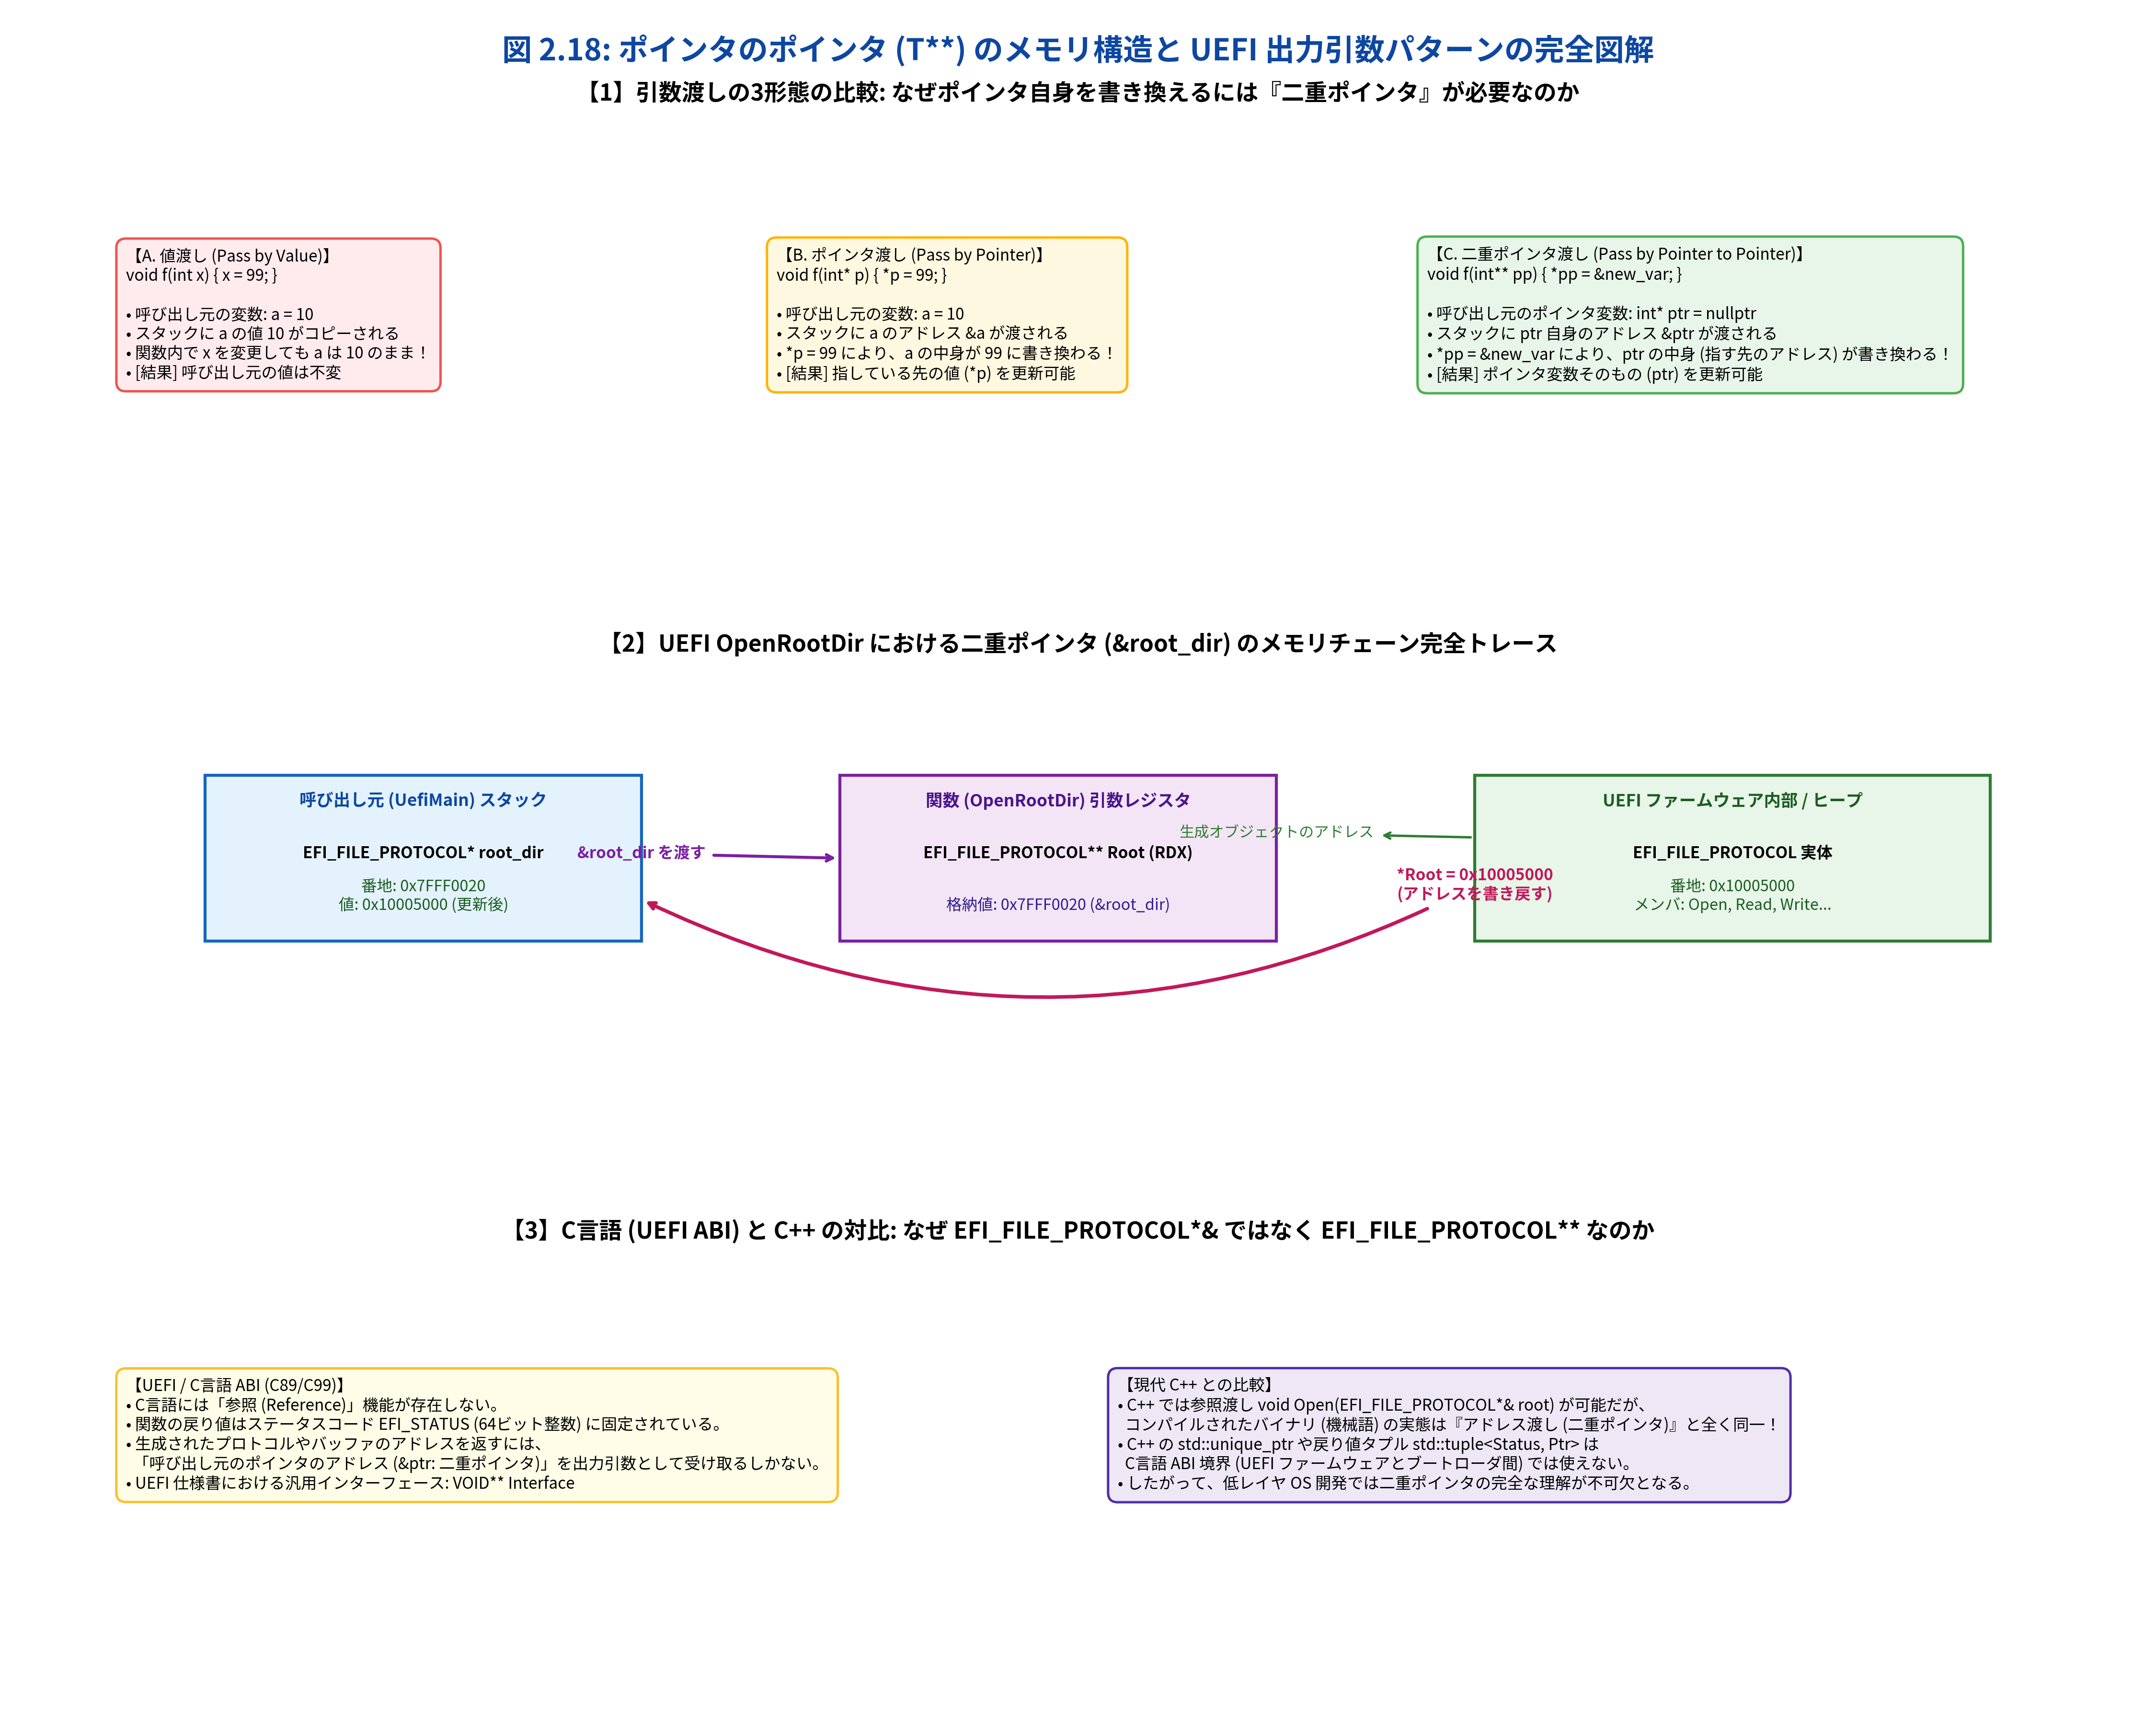

In [4]:
# 高解像度図版 Figure 2.18 の生成とインライン表示
from common.os_sim import plot_figure_2_18_double_pointer_and_uefi_interface
from IPython.display import Image, display

fig2_18_path = "result/fig2_18_double_pointer_and_uefi_interface.png"
plot_figure_2_18_double_pointer_and_uefi_interface(fig2_18_path)
print(f"図 2.18 を高解像度 (DPI 300) で生成しました: {fig2_18_path}")
display(Image(filename=fig2_18_path, width=950))


## 2.9.7 なぜ UEFI API は二重ポインタ（`&root_dir`）を要求するのか？

### 1. `OpenVolume` と `Open` の関数定義

第2章 2.6節でファイル保存を行う際、ルートディレクトリを開くために以下のコードを実行しました：

```cpp
EFI_FILE_PROTOCOL* root_dir;
fs->OpenVolume(fs, &root_dir);
```

この `fs->OpenVolume` のプロトタイプ宣言（UEFI 仕様書）を見てみましょう：

```c
typedef
EFI_STATUS
(EFIAPI *EFI_SIMPLE_FILE_SYSTEM_PROTOCOL_OPEN_VOLUME) (
    IN EFI_SIMPLE_FILE_SYSTEM_PROTOCOL  *This,
    OUT EFI_FILE_PROTOCOL               **Root
);
```

引数 `Root` の型が、まさに **`EFI_FILE_PROTOCOL**`（二重ポインタ）** になっています！
また、引数修飾子に `OUT` と書かれています。

### 2. なぜ戻り値でポインタを返さないのか？

現代の高級言語（Python や Go、Rust）であれば、以下のように複数の値をタプルで返したり、エラーを例外で投げるのが一般的です：

```python
# Python 的な世界観 (理想)
status, root_dir = fs.open_volume()
```

しかし、UEFI は 1990 年代後半に策定された **C言語（C89）ベースのバイナリインターフェース（ABI）**です。
C言語には以下の制約があります：
1. **関数の戻り値は1つしか返せない**:
   UEFI では、すべての関数の戻り値は `EFI_STATUS`（成功 `0`、エラーコード負数）を返すために予約されています。
2. **C言語には「参照（`&`）」が存在しない**:
   C++ であれば `void Open(EFI_FILE_PROTOCOL*& root)` と書けますが、純粋な C言語にはポインタしかありません。

したがって、関数が新しいハンドルやバッファ、プロトコルを生成して呼び出し元に届けるためには、**「呼び出し元のポインタ変数のアドレス（`&root_dir`）を出力引数として受け取り、関数内部で間接代入 `*Root = new_ptr;` を行う」**以外の方法が原理的に存在しないのです。

### 3. C++ 参照（`T*&`）との本質的同一性

現代 C++ では、参照渡しを使って以下のように書くことができます：

```cpp
void AllocateInCpp(EFI_FILE_PROTOCOL*& root) {
    root = &new_protocol_instance;
}
```

構文上は `*` が1つ減ってスッキリ見えますが、コンパイラが生成する機械語（アセンブリ）を逆アセンブルしてみると、**二重ポインタ `EFI_FILE_PROTOCOL**` を使った場合と1バイトの狂いもなく完全に同一**のコード（呼び出し元のスタックアドレスをレジスタで渡し、間接ストア）が生成されます。

つまり、二重ポインタは難解なトリックではなく、**「メモリ番地を持つ変数を別の関数から書き換える」というコンピュータの物理的本質そのもの**なのです。


In [5]:
# Python シミュレータによる二重ポインタと UEFI OpenRootDir パターンの動作検証
from common.os_sim import DoublePointerSimulator

dp_sim = DoublePointerSimulator(stack_base=0x7FFF_0020, heap_base=0x1000_5000)

# 1. UEFI ファームウェア内部で生成されるファイルオブジェクトをシミュレート
obj_addr = dp_sim.allocate_target_object("root_file_protocol", size=64)
print("=================================================================")
print(f"[ヒープ確保] EFI_FILE_PROTOCOL 実体アドレス: 0x{obj_addr:X}")
print("=================================================================")

# 2. 呼び出し元 (UefiMain) のスタック上にローカルポインタ変数を宣言 (nullptr で初期化)
ptr_addr = dp_sim.allocate_local_pointer("root_dir", target_address=0)
print(f"呼び出し元スタック上の変数 'root_dir' のアドレス: 0x{ptr_addr:X}")
print(f"呼び出し直前の root_dir の格納値           : 0x{dp_sim.dereference_pointer('root_dir'):X} (nullptr)")

# 3. 【実験 A】間違った値渡し (FailAlloc) をシミュレート
print("\n--- 実験 A: 値渡し (FailAlloc) の実行 ---")
res_fail = dp_sim.simulate_pass_by_value_failure("root_dir", obj_addr)
print(f"  呼び出し元のポインタは更新されたか? : {res_fail['is_caller_updated']} (失敗)")
print(f"  呼び出し後の root_dir の格納値      : 0x{res_fail['caller_ptr_value_after']:X} (nullptrのまま!)")
print(f"  理由: {res_fail['explanation']}")

# 4. 【実験 B】正しい二重ポインタ渡し (fs->OpenVolume(fs, &root_dir)) をシミュレート
print("\n--- 実験 B: 二重ポインタ渡し (Pass-by-Double-Pointer) の実行 ---")
res_succ = dp_sim.simulate_pass_by_double_pointer_success("root_dir", obj_addr)
print(f"  呼び出し元のポインタは更新されたか? : {res_succ['is_caller_updated']} (大成功!)")
print(f"  呼び出し後の root_dir の格納値      : 0x{res_succ['caller_ptr_value_after']:X}")
print(f"  理由: {res_succ['explanation']}")

assert res_succ['caller_ptr_value_after'] == obj_addr, "二重ポインタによる書き換えに失敗しました！"
print("\n[検証完了] 二重ポインタにより、呼び出し元のスタックポインタが正しく書き換わることを実証しました。")


[ヒープ確保] EFI_FILE_PROTOCOL 実体アドレス: 0x10005000
呼び出し元スタック上の変数 'root_dir' のアドレス: 0x7FFF0020
呼び出し直前の root_dir の格納値           : 0x0 (nullptr)

--- 実験 A: 値渡し (FailAlloc) の実行 ---
  呼び出し元のポインタは更新されたか? : False (失敗)
  呼び出し後の root_dir の格納値      : 0x0 (nullptrのまま!)
  理由: Callee modified its local copy on stack; caller's pointer remains unchanged (0x0 nullptr)

--- 実験 B: 二重ポインタ渡し (Pass-by-Double-Pointer) の実行 ---
  呼び出し元のポインタは更新されたか? : True (大成功!)
  呼び出し後の root_dir の格納値      : 0x10005000
  理由: Callee dereferenced *pp and wrote allocated_obj_addr directly into caller's stack variable

[検証完了] 二重ポインタにより、呼び出し元のスタックポインタが正しく書き換わることを実証しました。


## 2.9.8 C++20 による構造体レイアウト・アロー演算子・二重ポインタ完全検証

本節で導出したすべての理論（構造体アライメント、パディング、アロー演算子とドット演算子の等価性、機械語レベルのオフセット解決、二重ポインタによる出力引数パターン）を、ホスト側 C++20（`src/ch02/arrow_operator_sim.cpp`）でスタンドアロン検証します。

以下のコードセルを実行して、コンパイル・実行および単体テストがパスすることを確認しましょう。


In [6]:
# C++20 スタンドアロン検証コードのビルドと実行
import subprocess

cpp_source = "src/ch02/arrow_operator_sim.cpp"
if not os.path.exists(cpp_source):
    cpp_source = "../src/ch02/arrow_operator_sim.cpp"

cmd_compile = ["g++", "-std=c++20", "-O2", "-Wall", "-Wextra", cpp_source, "-o", "/tmp/arrow_operator_sim"]
print("C++20 検証コードをコンパイル中:", " ".join(cmd_compile))
subprocess.run(cmd_compile, check=True)

print("コンパイル成功！実行結果:\n")
res = subprocess.run(["/tmp/arrow_operator_sim"], capture_output=True, text=True)
print(res.stdout)


C++20 検証コードをコンパイル中: g++ -std=c++20 -O2 -Wall -Wextra ../src/ch02/arrow_operator_sim.cpp -o /tmp/arrow_operator_sim


コンパイル成功！実行結果:

  MikanOS Chapter 2.9: Struct Memory Layout, Arrow Operator, & Double Pointers 

[1] Struct Memory Layout & Alignment Math:
  - sizeof(SampleStruct)        : 16 bytes
  - alignof(SampleStruct)       : 8 bytes
  - offsetof(SampleStruct, a)   : 0 bytes (uint32_t, 4B)
  - offsetof(SampleStruct, b)   : 4 bytes (uint8_t,  1B)
  - [Padding at Offset 5]       : 1 byte (satisfying 2-byte alignment for uint16_t)
  - offsetof(SampleStruct, c)   : 6 bytes (uint16_t, 2B)
  - offsetof(SampleStruct, d)   : 8 bytes (uint64_t, 8B)

[2] Arrow Operator (->) vs Dereference Dot ((*p).member) Equivalence:
  - Syntax sugar identity       : p->member == (*p).member
  - Machine code translation    : MOV REG, [RDI + offset]
  - Manual offset validation    : PASSED

[3] Column 2.2: Pointer to Pointer (Double Pointer T**) Semantics:
  - Pass-by-Value failure       : CONFIRMED (Caller unmodified)
  - Pass-by-Double-Pointer      : SUCCESS (*pp = target)
  - C++ Reference comparison    : IDENTICAL AT

## 2.9.9 演習と理解度チェック（自己採点クイズ）

本節で学んだ知識の定着を確認するため、以下の5つの問題に挑戦してください。

---

### 【問1】構造体アライメント数理
以下の構造体が 64ビット環境（GCC / Clang）でコンパイルされたとき、`sizeof(MyStruct)` は何バイトになるでしょうか？
```cpp
struct MyStruct {
    uint8_t  a;
    uint32_t b;
    uint8_t  c;
};
```
- (A) 6 バイト
- (B) 8 バイト
- (C) 12 バイト
- (D) 16 バイト

---

### 【問2】アロー演算子の構文
ポインタ変数 `p` を使って構造体メンバ `x` にアクセスする式として、`p->x` と完全に等価な正しい C/C++ 構文はどれでしょうか？
- (A) `*p.x`
- (B) `(*p).x`
- (C) `&(p.x)`
- (D) `p.*x`

---

### 【問3】機械語レベルの動作
ポインタ `p` がレジスタ `RDI` に格納されているとき、`p->member`（`member` のオフセットが 16 バイト、64ビット整数）をレジスタ `RAX` にロードする x86-64 アセンブリ命令はどれでしょうか？
- (A) `MOV RAX, [RDI + 16]`
- (B) `LEA RAX, [RDI + 16]`
- (C) `MOV [RDI], RAX`
- (D) `PUSH [RDI + 16]`

---

### 【問4】コラム 2.2 二重ポインタのデリファレンス
`int x = 100; int* p = &x; int** pp = &p;` のとき、`*pp` の値（評価結果）は何を表しているでしょうか？
- (A) 整数値 `100`
- (B) 変数 `x` のメモリアドレス（ポインタ `p` の格納値）
- (C) ポインタ変数 `pp` 自身のメモリアドレス
- (D) 不定値（未定義動作）

---

### 【問5】UEFI 出力引数パターン
関数 `EFI_STATUS OpenRootDir(..., EFI_FILE_PROTOCOL** Root)` を呼び出す際、ローカル変数 `EFI_FILE_PROTOCOL* root = nullptr;` を渡す正しい書き方はどれでしょうか？
- (A) `OpenRootDir(..., root);`
- (B) `OpenRootDir(..., *root);`
- (C) `OpenRootDir(..., &root);`
- (D) `OpenRootDir(..., (EFI_FILE_PROTOCOL**)root);`


In [7]:
# === 理解度チェッククイズ自己採点プログラム ===
def grade_chapter2_9_quiz(answers: dict[str, str]):
    correct_answers = {
        "Q1": "C",  # a(1) + pad(3) + b(4) + c(1) + tail_pad(3) = 12 bytes (max align 4)
        "Q2": "B",  # (*p).x
        "Q3": "A",  # MOV RAX, [RDI + 16]
        "Q4": "B",  # *pp is the value of p (&x)
        "Q5": "C",  # &root (address of pointer variable)
    }

    explanations = {
        "Q1": "uint8_t a (offset 0), uint32_t b のために 3B パディング (offset 4, size 4), uint8_t c (offset 8, size 1)。最大アライメント 4 の倍数に切り上げるため末尾に 3B パディングが入り、合計 12 バイトとなります。",
        "Q2": "演算子優先順位により . は * より高いため、*p.x は *(p.x) と解釈されてエラーになります。括弧をつけた (*p).x が正解です。",
        "Q3": "CPU はベースレジスタ RDI に即値オフセット 16 を加算した番地からメモリ値をロードする MOV RAX, [RDI + 16] を実行します。",
        "Q4": "pp は &p です。1回デリファレンスした *pp は p の格納値、すなわち x のアドレス (&x) です。**pp で 100 になります。",
        "Q5": "関数内でポインタ変数 root そのものを書き換えてもらうため、root のアドレス &root を渡す必要があります。",
    }

    score = 0
    total = len(correct_answers)
    print("=================================================================")
    print("  第2章 2.9節 理解度チェック 採点結果")
    print("=================================================================")

    for q, user_ans in answers.items():
        corr = correct_answers.get(q)
        user_clean = user_ans.strip().upper()
        if user_clean == corr:
            score += 1
            print(f"[{q}] 正解 (○): 選択肢 ({user_clean})")
        else:
            print(f"[{q}] 不正解 (×): あなたの回答 ({user_clean}) -> 正解 ({corr})")
        print(f"      解説: {explanations[q]}\n")

    percent = (score / total) * 100
    print(f"合計得点: {score} / {total} 問 ({percent:.1f}%)")
    if score == total:
        print("\033[32m★ 満点です！構造体アライメント、アロー演算子、および二重ポインタを完璧にマスターしました！\033[0m")
    else:
        print("\033[33m解説を復習して、間違えた箇所を再確認してみましょう。\033[0m")

# あなたの回答を記入して実行してください
my_answers = {
    "Q1": "C",
    "Q2": "B",
    "Q3": "A",
    "Q4": "B",
    "Q5": "C",
}

grade_chapter2_9_quiz(my_answers)


  第2章 2.9節 理解度チェック 採点結果
[Q1] 正解 (○): 選択肢 (C)
      解説: uint8_t a (offset 0), uint32_t b のために 3B パディング (offset 4, size 4), uint8_t c (offset 8, size 1)。最大アライメント 4 の倍数に切り上げるため末尾に 3B パディングが入り、合計 12 バイトとなります。

[Q2] 正解 (○): 選択肢 (B)
      解説: 演算子優先順位により . は * より高いため、*p.x は *(p.x) と解釈されてエラーになります。括弧をつけた (*p).x が正解です。

[Q3] 正解 (○): 選択肢 (A)
      解説: CPU はベースレジスタ RDI に即値オフセット 16 を加算した番地からメモリ値をロードする MOV RAX, [RDI + 16] を実行します。

[Q4] 正解 (○): 選択肢 (B)
      解説: pp は &p です。1回デリファレンスした *pp は p の格納値、すなわち x のアドレス (&x) です。**pp で 100 になります。

[Q5] 正解 (○): 選択肢 (C)
      解説: 関数内でポインタ変数 root そのものを書き換えてもらうため、root のアドレス &root を渡す必要があります。

合計得点: 5 / 5 問 (100.0%)
★ 満点です！構造体アライメント、アロー演算子、および二重ポインタを完璧にマスターしました！


## 2.9.10 まとめと第3章への展望

### 1. 本節のまとめ

本節では、OS 開発・UEFI プログラミングの中核を担う構造体ポインタ操作と二重ポインタについて、理論・数理・実装の両面から深く学びました。

1. **アロー演算子（`->`）の正体**:
   - `p->member` は `(*p).member` と完全に同等なシンタックスシュガー。
   - x86-64 アセンブリレベルでは、`MOV REG, [RDI + offset]` というベースレジスタ＋オフセット修飾命令に翻訳される。
2. **構造体のアライメントとパディング数理**:
   - 自然アライメント要件（$	ext{Address} \pmod{	ext{Align}} == 0$）を満たすため、コンパイラはメンバ間にパディング（隙間バイト）を自動挿入する。
   - 構造体全体のサイズは、最大メンバアライメントの倍数に切り上げられる。
3. **コラム 2.2「ポインタのポインタ（二重ポインタ `T**`）」の真価**:
   - 引数渡しは常にコピー（値渡し）である。
   - 呼び出し元の「ポインタ変数そのもの」を関数内で書き換えるには、ポインタ変数のアドレス（`&ptr`: 二重ポインタ）を渡す以外に方法がない。
   - UEFI API が `EFI_FILE_PROTOCOL**` などの二重ポインタを要求するのは、C言語 ABI における出力引数（Output Parameter）パターンの必然である。

---

### 2. 第2章の完結と第3章への架橋

これにて、**第2章「EDK II 入門とメモリマップ」の全節の解説が完了**しました！

- **2.1〜2.2節**: EDK II ビルド機構と `MikanLoaderPkg` のハローワールド
- **2.3〜2.4節**: 物理メモリ空間・MMIO アーキテクチャと UEFI メモリマップ構造体
- **2.5〜2.7節**: `GetMemoryMap()` の取得、CSV ファイル出力、および利用可能 RAM の集計分析
- **2.8〜2.9節**: 64ビットポインタの基礎数理、構造体メモリレイアウト、アロー演算子、および二重ポインタ

低レイヤのメモリとポインタを自在に操る基礎力を手に入れた私たちは、いよいよ次章**「第3章 画面表示の練習とブートローダ」**へと進みます！

第3章では、以下のエキサイティングなテーマに挑みます：
- **UEFI GOP (Graphics Output Protocol)** によるフレームバッファの物理アドレス取得とピクセル直接描画
- **C言語による最小カーネル**の作成と、ブートローダからカーネルへのメモリ展開
- ブートローダからカーネルのエントリポイントへの**関数ポインタによるジャンプ**
- System V AMD64 ABI の最大の罠である **Red Zone（128バイト）** と `-mno-red-zone` の技術的必然性

OS 自作の真骨頂であるカーネルブートの世界へ、自信を持って踏み出しましょう！
